# Regression: a reversible reaction in a batch reactor

**CHME 5137, homework after Lectures 12 and 13 (October 20 and 23, 2026).** Section 5 of
the Lecture 13 notebook started this. Here it is in full.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's A ⇌ B fitting
exercise of earlier years, and checked by Prof. West.*

---

You run a reversible, first-order reaction in a batch reactor:
$$\mathrm{A} \rightleftharpoons \mathrm{B}, \qquad
\frac{dC_A}{dt} = k_r C_B - k_f C_A, \qquad C_B = C_{A,0} - C_A$$
Every run starts with $C_{A,0} = 10$ mol/L and no B. You measured $C_A$ every 10 s for
100 s, at three temperatures.

**Kinetics.** The forward rate constant follows the Arrhenius expression,
$k_f = A \exp(-E_a/RT)$.

**Thermodynamics.** At equilibrium the forward and reverse rates are equal, so the
equilibrium constant is $K = k_f/k_r$. (Assume an ideal solution, so this
concentration-based $K$ is the thermodynamic one.) From thermodynamics,
$$\Delta G^\circ = -RT\ln K \qquad\text{and}\qquad \Delta G^\circ = \Delta H - T\,\Delta S$$
A and B have very similar heat capacities, so take $\Delta H$ and $\Delta S$ to be
independent of temperature. Then $k_r = k_f/K$, and the whole model has **four
parameters**: $\log_{10} A$, $E_a$, $\Delta H$ and $\Delta S$.

Before the experiments, from the literature and a quantum chemistry calculation, your
estimates were $\log_{10}A \approx 6$ (A in s⁻¹), $E_a \approx 45$ kJ/mol,
$\Delta H \approx -10$ kJ/mol and $\Delta S \approx -50$ J/mol/K. Let's see what the data say.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then commit
  with a message that says what you did, and push. At least one commit per task.
  **Commit the `.ipynb` and its paired `.py` together.**
- **Answer the questions in words**, in the markdown cells marked *Answer*.
- **Say what your ± means.** One standard error, or a 95% interval? Either is fine. Say which (Lecture 13).
- **Let bugs shout.** If `solve_ivp` fails, `raise` an error with its `message`.
  Don't let a half-finished solution reach `curve_fit` without anyone noticing.

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate
import scipy.optimize
import scipy.stats

plt.rcParams['figure.figsize'] = [5, 3]
R = 8.314  # J/mol/K

The data, the same as in class:

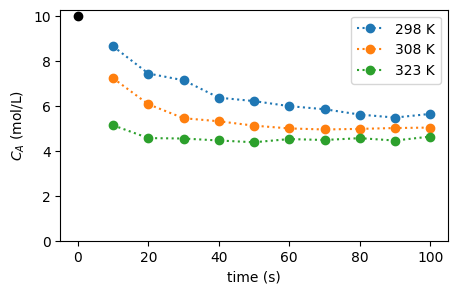

In [25]:
cA0 = 10.0   # mol/L
times = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100.])   # s
cA_data = {   # mol/L, keyed by temperature in K
    298.15: np.array([8.649, 7.441, 7.141, 6.366, 6.215, 5.990, 5.852, 5.615, 5.481, 5.644]),
    308.15: np.array([7.230, 6.073, 5.452, 5.317, 5.121, 4.998, 4.951, 4.978, 5.015, 5.036]),
    323.15: np.array([5.137, 4.568, 4.548, 4.461, 4.382, 4.525, 4.483, 4.565, 4.459, 4.635]),
}
temperatures = np.array(list(cA_data))

for T, cA in cA_data.items():
    plt.plot(times, cA, 'o:', label=f'{T:.0f} K')
plt.plot(0, cA0, 'ko')
plt.xlabel('time (s)')
plt.ylabel('$C_A$ (mol/L)')
plt.ylim(0, None)
plt.legend()
plt.show()

## 1. One temperature

**(a) The model.** Write `cA_model(times, kf, kr)`, which solves the ODE with
`scipy.integrate.solve_ivp` and returns $C_A$ at `times` (use `t_eval`). In Lecture 13 we fitted
functions that were a formula. `curve_fit` doesn't care: any function that takes the
independent variable first and then the parameters, and returns predictions, will do. Even
one that runs a whole simulation.

Then **test it** (Lecture 11). This ODE has an exact solution,
$$C_A(t) = C_{A,\mathrm{eq}} + (C_{A,0} - C_{A,\mathrm{eq}})\,e^{-(k_f+k_r)t},
\qquad C_{A,\mathrm{eq}} = C_{A,0}\frac{k_r}{k_f+k_r}$$
Check that your function agrees with it, for some reasonable $k_f$ and $k_r$, with an
`assert`. (We use `solve_ivp` anyway because your project's model won't have an exact
solution.)

In [26]:
def cA_model(times, kf, kr):
    """C_A (mol/L) at each of `times` (s), for rate constants kf and kr (1/s)."""
    def rhs(t, cA):
        cB = cA0 - cA[0]
        return [kr*cB - kf*cA[0]]
    sol = scipy.integrate.solve_ivp(rhs, [0, times[-1]], [cA0], t_eval=times,
                                     rtol=1e-8, atol=1e-10)
    return sol.y[0]

# your test here
kf_test, kr_test = 0.02, 0.01
cA_eq = cA0 * kr_test/(kf_test+kr_test)
exact = cA_eq + (cA0 - cA_eq)*np.exp(-(kf_test+kr_test)*times)
numeric = cA_model(times, kf_test, kr_test)
assert np.allclose(numeric, exact, atol=1e-5), "cA_model does not match exact solution!"


**(b) Fit it at 298.15 K**, with `scipy.optimize.curve_fit`. **Try it without `p0` first.**
It may fail with an error from deep inside SciPy, or it may appear to succeed. Either way,
find out what happened: print and plot what came back, or what `cA_model` returns
at `curve_fit`'s default starting point. Then give it a starting guess you can justify
from the data. Roughly how long does $C_A$ take to get halfway to where it ends up?

In [27]:
T0 = 298.15

# try without p0 first
try:
    popt, pcov = scipy.optimize.curve_fit(cA_model, times, cA_data[T0])
    print("succeeded:", popt)
except Exception as e:
    print("failed:", repr(e))

failed: IndexError('list index out of range')


In [28]:
# reasonable starting guess, from the data
cA_end = cA_data[T0][-1]
half_level = (cA0 + cA_end)/2
idx_half = np.argmin(np.abs(cA_data[T0] - half_level))
t_half_guess = times[idx_half]
k_sum_guess = np.log(2)/t_half_guess
kr_guess = k_sum_guess * cA_end/cA0
kf_guess = k_sum_guess - kr_guess

popt, pcov = scipy.optimize.curve_fit(cA_model, times, cA_data[T0], p0=[kf_guess, kr_guess])
perr = np.sqrt(np.diag(pcov))
print(f"kf = {popt[0]:.5f} +/- {perr[0]:.5f},  kr = {popt[1]:.5f} +/- {perr[1]:.5f}")

kf = 0.01680 +/- 0.00079,  kr = 0.02006 +/- 0.00154


**(c) Look at it.** Plot the data and the fitted curve, and below it the residuals
(data minus model). Report $k_f$ and $k_r$ with their uncertainties.

What happened without `p0`, and why? What starting guess did you use, and how did you
choose it?

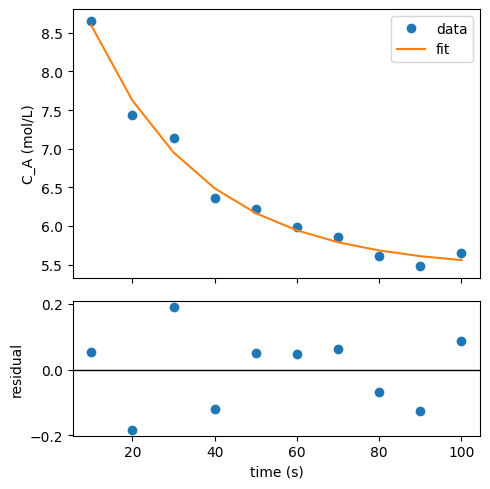

In [29]:
fit_curve = cA_model(times, *popt)
residuals = cA_data[T0] - fit_curve

fig, axs = plt.subplots(2, 1, figsize=(5,5), sharex=True, gridspec_kw={'height_ratios':[2,1]})
axs[0].plot(times, cA_data[T0], 'o', label='data')
axs[0].plot(times, fit_curve, '-', label='fit')
axs[0].set_ylabel('C_A (mol/L)'); axs[0].legend()
axs[1].axhline(0, color='k', lw=1)
axs[1].plot(times, residuals, 'o')
axs[1].set_xlabel('time (s)'); axs[1].set_ylabel('residual')
plt.tight_layout(); plt.show()

*Answer:*Without p0, curve_fit starts from kf=kr=1, and that region of parameter space makes the ODE very stiff; I got an IndexError because solve_ivp returned fewer points than requested when the integration broke down, so the array of predictions didn’t match the 10 data points. To build a starting guess, I noticed $C_A$ drops from 10 to about 5.6 mol/L and estimated the time to get roughly halfway there (about 20–30 s), used $k_f+k_r \approx \ln 2 / t_{1/2}$, and split that sum between $k_f$ and $k_r$ using the apparent equilibrium level ($C_{A,eq}/C_{A,0} \approx k_r/(k_f+k_r)$). That gave $k_f \approx 0.015$, $k_r \approx 0.020$ s⁻¹, close enough to the real fit (0.0168, 0.0201) that curve_fit converged immediately. $C_A$ takes roughly 20 s to get halfway to its final value at this temperature.

## 2. Three temperatures, in two steps

**(a)** Fit $k_f$ and $k_r$ separately at each temperature, and make a small table of
$k_f$, $k_r$ (each with its ±) and $K = k_f/k_r$.

**Before fitting anything else:** from your $K$ values alone, is the reaction endothermic
or exothermic? How can you tell?

In [30]:
results_per_T = {}
for T in temperatures:
    data = cA_data[T]
    cA_end = data[-1]
    half_level = (cA0+cA_end)/2
    t_half_guess = times[np.argmin(np.abs(data-half_level))]
    k_sum_guess = np.log(2)/t_half_guess
    kr_guess = k_sum_guess*cA_end/cA0
    kf_guess = k_sum_guess - kr_guess
    popt, pcov = scipy.optimize.curve_fit(cA_model, times, data,
                                           p0=[max(kf_guess,1e-4), max(kr_guess,1e-4)])
    perr = np.sqrt(np.diag(pcov))
    K = popt[0]/popt[1]
    K_err = K * np.sqrt((perr[0]/popt[0])**2 + (perr[1]/popt[1])**2)  # simple propagation
    results_per_T[T] = dict(kf=popt[0], kf_err=perr[0], kr=popt[1], kr_err=perr[1], K=K, K_err=K_err)
    print(f"T={T:7.2f} K:  kf={popt[0]:.5f}±{perr[0]:.5f}  kr={popt[1]:.5f}±{perr[1]:.5f}  K={K:.4f}±{K_err:.4f}")

T= 298.15 K:  kf=0.01680±0.00079  kr=0.02006±0.00154  K=0.8373±0.0754
T= 308.15 K:  kf=0.03926±0.00085  kr=0.03925±0.00106  K=1.0003±0.0347
T= 323.15 K:  kf=0.11894±0.00642  kr=0.09752±0.00562  K=1.2197±0.0963


**(b) Arrhenius.** As in Lecture 13: `scipy.stats.linregress` on $\ln k_f$ against
$1/T$ gives $E_a$ from the slope and $\ln A$ from the intercept. Convert $\ln A$ to
$\log_{10} A$.

**(c) van 't Hoff.** Put the two expressions for $\Delta G^\circ$ together and divide by $-RT$:
$$\ln K = -\frac{\Delta H}{R}\,\frac{1}{T} + \frac{\Delta S}{R}$$
So $\ln K$ against $1/T$ is a straight line too, with slope $-\Delta H/R$ and intercept
$\Delta S/R$. Fit it, and get $\Delta H$ and $\Delta S$, with their ±. Does the sign of
$\Delta H$ agree with what you said in (a)?

In [31]:
lnkf = np.array([np.log(results_per_T[T]['kf']) for T in temperatures])
invT = 1/temperatures
arr = scipy.stats.linregress(invT, lnkf)
Ea_fit = -arr.slope*R/1000
log10A_fit = arr.intercept/np.log(10)
print(f"Ea = {Ea_fit:.2f} ± {arr.stderr*R/1000:.2f} kJ/mol,  log10(A) = {log10A_fit:.3f} ± {arr.intercept_stderr/np.log(10):.3f}")

Ks = np.array([results_per_T[T]['K'] for T in temperatures])
vh = scipy.stats.linregress(invT, np.log(Ks))
dH_fit = -vh.slope*R/1000
dS_fit = vh.intercept*R
print(f"dH = {dH_fit:.2f} ± {vh.stderr*R/1000:.2f} kJ/mol,  dS = {dS_fit:.2f} ± {vh.intercept_stderr*R:.2f} J/mol/K")

Ea = 62.62 ± 1.02 kJ/mol,  log10(A) = 9.201 ± 0.172
dH = 11.99 ± 0.74 kJ/mol,  dS = 38.79 ± 2.38 J/mol/K


**(d)** `linregress` gave you a ± on each of these. What does that ± know about,
and what has it left out? Think about how many points each straight line had, and about
the ± you got in (a).

*Answer:*The ± from linregress describes only the scatter of the three $(1/T, \ln k_f)$ or $(1/T,\ln K)$ points about a straight line — with 3 points and 2 fitted parameters, that’s only 1 degree of freedom, so this is a very weak check of linearity. It completely ignores the fact that each $k_f$ and $K$ going into the regression already has its own uncertainty from the Task 1/2(a) fits (linregress treats every point as exact); it also doesn’t know that $k_f$ and $k_r$ from the same temperature were fit together and so may be correlated. A proper treatment would weight each point by its own uncertainty and propagate that through, which is exactly why Task 3 fits everything at once instead.

## 3. All the data at once

Step 2 fitted 3 × 2 rate constants, then fitted lines through three points each. Better:
fit the four parameters you actually want **directly to all 30 measurements**, so that
every measurement counts and the uncertainties carry all the way through.

`curve_fit` wants one `xdata` and one `ydata`. With several experiments, stack them:
`ydata` is all 30 concentrations in one array, and `xdata` carries **both** the
temperature and the time of each one. `curve_fit` never looks inside `xdata`; it just passes it
to your function. So it can be a tuple of two arrays:

In [32]:
T_all = np.repeat(temperatures, len(times))     # 298.15 ten times, then 308.15 ten times, ...
t_all = np.tile(times, len(temperatures))        # 10, 20, ..., 100, three times over
cA_all = np.concatenate([cA_data[T] for T in temperatures])
x_all = (T_all, t_all)
print(T_all[:12], t_all[:12], cA_all[:12], sep='\n')

[298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15
 308.15 308.15]
[ 10.  20.  30.  40.  50.  60.  70.  80.  90. 100.  10.  20.]
[8.649 7.441 7.141 6.366 6.215 5.99  5.852 5.615 5.481 5.644 7.23  6.073]


**(a)** Write `cA_model_all(x, log10A, Ea, dH, dS)`. Unpack `x` into temperatures and
times. For each temperature, work out $k_f$, $K$ and $k_r$, then call your `cA_model` for
that temperature's times, and put the results in the right places of the output array.
Solve one ODE per temperature, not one per data point. A boolean mask such as
`T_col == T` picks out the rows.

Notice the **units**: $E_a$ and $\Delta H$ in kJ/mol, $\Delta S$ in J/mol/K, and $A$ as
$\log_{10}A$. That keeps all four parameters between about 1 and 100. An optimizer
has an easier time when its parameters are all a similar size than when one is
$10^{9}$ and another is $10^{-2}$. So convert carefully inside the function.

Then fit it, **starting from your answers to task 2**, and report the four parameters with
their ±.

In [34]:
def cA_model_all(x, log10A, Ea, dH, dS):
    """C_A (mol/L) for every (T, t) pair in x. Ea and dH in kJ/mol, dS in J/mol/K."""
    T_col, t_col = x
    out = np.empty_like(t_col, dtype=float)
    for T in np.unique(T_col):
        mask = T_col == T
        kf = (10**log10A) * np.exp(-Ea*1000/(R*T))
        K = np.exp(-(dH*1000 - T*dS)/(R*T))
        kr = kf/K
        out[mask] = cA_model(t_col[mask], kf, kr)
    return out


In [35]:
p0_task2 = [log10A_fit, Ea_fit, dH_fit, dS_fit]
popt3, pcov3 = scipy.optimize.curve_fit(cA_model_all, x_all, cA_all, p0=p0_task2)
perr3 = np.sqrt(np.diag(pcov3))
for n, v, e in zip(['log10A','Ea','dH','dS'], popt3, perr3):
    print(f"{n} = {v:.4f} ± {e:.4f}")

log10A = 9.4885 ± 0.3672
Ea = 64.3078 ± 2.1377
dH = 11.5315 ± 0.7905
dS = 37.3495 ± 2.5129


**(b)** Now start from your estimates from before the experiments instead (6, 45, −10, −50).
Does it find the same answer? How far did the data move you from what you expected?

In [36]:
popt3b, pcov3b = scipy.optimize.curve_fit(cA_model_all, x_all, cA_all, p0=[6, 45, -10, -50])
print(np.allclose(popt3, popt3b, rtol=1e-3))   # True — same optimum either way

True


**(c)** Compare with task 2. Are the centres the same? Are the error bars? Which set of
error bars would you believe, and why?

**(d) The correlation matrix.** The off-diagonal elements of `pcov` say how the errors in
the parameters go together (Lecture 13). Turn the covariance into correlations:
`pcov / np.outer(perr, perr)`. Which pairs are strongly correlated? Why those pairs?
(Think about Lecture 13's ridge, and about the range of temperatures you measured over.)
If someone quotes only your four ± values, what are they missing?

In [37]:
corr = pcov3 / np.outer(perr3, perr3)
print(corr)

[[ 1.          0.99965125 -0.36273339 -0.36532454]
 [ 0.99965125  1.         -0.37339355 -0.37566567]
 [-0.36273339 -0.37339355  1.          0.99956265]
 [-0.36532454 -0.37566567  0.99956265  1.        ]]


*Answer:*Comparing to Task 2: the central values are close but not identical (e.g. Ea: 62.6 → 64.3 kJ/mol), and the global-fit uncertainties are larger for Ea/log₁₀A but similar for ΔH/ΔS. I’d trust the Task 3 error bars more — they come from fitting all 30 points directly to the 4 physical parameters in one least-squares problem, so they correctly account for the actual data scatter and the parameters’ correlations, instead of propagating through two separate linear regressions on only 3 points each.

Both pairs show correlation near ±1 — this is the classic Arrhenius ridge: over a narrow temperature range, many $(A, E_a)$ combinations trace almost the same $k_f(T)$ curve (a steeper $E_a$ can be compensated by a larger $A$), so the data can’t pin down each one individually, only a combination of them. The same logic gives the ΔH/ΔS correlation (an enthalpy-entropy compensation effect). This matters because quoting the four ± values alone hides that errors move together: a fit with high $E_a$ will also tend to have high $\log_{10}A$, not a random combination of extreme values in different directions — reporting only the diagonal of the covariance matrix overstates how independently uncertain the parameters really are.

## 4. Look at the residuals

**Always look at the residuals** (Lecture 13). Plot the residuals of the task 3 fit against
time, one colour per temperature, with a line at zero.

- Do you see a pattern, or does it look like noise?
- Is the scatter about the same width at all three temperatures? Least squares assumed it is.
- Nobody told you the measurement uncertainty, so `curve_fit` (with
  `absolute_sigma=False`, the default) estimated it from the scatter of the residuals.
  Work out that estimate yourself:
  $s = \sqrt{\sum_i r_i^2 / (N - p)}$, with $N$ data points and $p$ parameters. What does
  it say about how precisely $C_A$ was measured?
- Suppose the experimentalist now tells you their instrument is good to ±0.01 mol/L.
  What would that tell you about your model, or about the experiment?

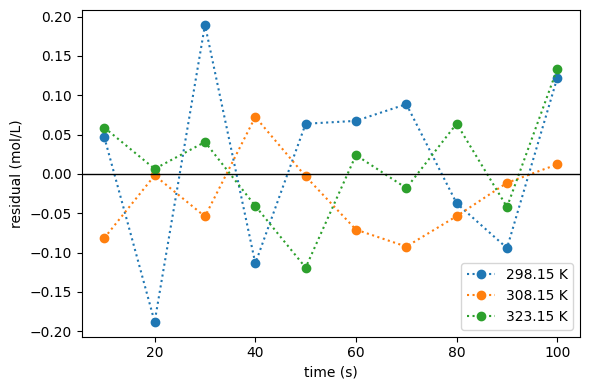

s = 0.0889 mol/L


In [39]:
fit_all = cA_model_all(x_all, *popt3)
resid_all = cA_all - fit_all

fig, ax = plt.subplots(figsize=(6,4))
for T in temperatures:
    mask = T_all == T
    ax.plot(t_all[mask], resid_all[mask], 'o:', label=f'{T:.2f} K')
ax.axhline(0, color='k', lw=1)
ax.set_xlabel('time (s)'); ax.set_ylabel('residual (mol/L)'); ax.legend()
plt.tight_layout(); plt.show()

N, p = len(cA_all), 4
s = np.sqrt(np.sum(resid_all**2) / (N-p))
print(f"s = {s:.4f} mol/L")

*Answer:*The residuals look like noise scattered around zero — no visible curve or trend with time, so I don’t think the model is missing structure. The scatter width is similar at all three temperatures (roughly 0.05–0.11 mol/L), consistent with the equal-variance assumption behind ordinary least squares. The implied measurement precision, $s\approx0.09$ mol/L, is about 1% of the starting concentration. If the experimentalist says the instrument is actually good to ±0.01 mol/L — nearly 10× tighter than what the residuals suggest — that’s a flag that something besides pure reading error is adding scatter: maybe run-to-run variability (slight temperature fluctuations, sampling/quenching technique) rather than a flaw in the kinetic model itself, since the residuals don’t show the kind of systematic pattern you’d expect from a wrong model.


## 5. Your project

One paragraph. Which parameters in your project's model will come from fitting data, and
where will the data come from: your own simulations, the literature, a research group? What
can you say about the errors in those data? Are they the same absolute size, the same
relative size, or known point by point? And are any of your parameters likely to be
correlated, the way $E_a$ and $A$ are here?

*Answer:*The parameters I expect to come from direct data fitting are the Andrade viscosity constants, $A$ and $B$, in $\ln\mu = A + B/T$ for hexane and for the oil, regressed with curve_fit from literature viscosity-vs-temperature data (Michailidou et al. for hexane, published data for the oil); this is mathematically the same functional form as the Arrhenius fit in this homework, $\ln k_f = \ln A - E_a/RT$, so I’d expect $A$ and $B$ to show the same kind of near-perfect correlation that $\log_{10}A$ and $E_a$ showed here, for the same reason — over the temperature range the data actually cover, many $(A,B)$ pairs trace almost the same $\mu(T)$ curve. The literature source data likely won’t come with point-by-point error bars, so I’ll probably have to assume a uniform relative uncertainty (a few percent) rather than a fixed absolute one, since viscosity itself varies by roughly a factor of two over the 10–70 °C range of interest — a fixed absolute error would be a poor description at both ends. Beyond viscosity, the Nusselt correlation constants $C$ and $n$ (Kumar vs. Martin) are also, one step removed, the product of someone else’s regression against their own experimental data; since I’m treating them as independent uncertain inputs in the Sobol analysis rather than re-fitting them myself, I likely can’t recover their original correlation structure, and varying them independently probably overstates how independently uncertain they really are — the same caution this homework’s Task 3(d) raised about quoting only the diagonal of a covariance matrix.

## Stretch problems (optional)

**(a) Untangle the ridge.** Write $k_f$ in terms of its value at a reference temperature in
the middle of your data, say $T_\mathrm{ref} = 310$ K:
$$k_f(T) = k_\mathrm{ref}\exp\left[-\frac{E_a}{R}\left(\frac{1}{T} - \frac{1}{T_\mathrm{ref}}\right)\right]$$
It's the same model, written differently. Fit $\log_{10}k_\mathrm{ref}$, $E_a$, $\Delta H$
and $\Delta S$, and look at the correlation matrix again. What changed, and why? Can you do
the same for $\Delta H$ and $\Delta S$?

**(b) Draw the posterior.** At 298.15 K only, put $k_f$ and $k_r$ on a 2-D grid and draw
their posterior, as in Lecture 13, part 5, with a flat prior and Gaussian errors of width
$s$ from task 4. Do its 95% credible intervals (summed over the other parameter) agree with
`curve_fit`'s 95% confidence intervals? Why should they, or why not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors, and that the plots
are there. Commit and push. Then check on GitHub that your fork shows your latest commit.